# Supervised NMF: sitar and tabla

This experiment learns frequency templates from the solo sitar and tabla recordings, then uses those templates to estimate their contributions to `outputs/synthetic_mixture.wav`. NMF templates are trained separately from each solo recording, so the source group is known; individual template indices are not instrument labels.

The recordings are separate performances, not aligned stems from one real performance. However, the exact samples used to create this synthetic mixture are available, so after reproducing the preprocessing and gains below they provide references for a **controlled synthetic test only**. Results do not establish real-world separation quality.

## Inputs and settings

Only the first 30 seconds are read from each file. The STFT and inverse STFT use the same settings as the earlier NMF notebooks. Four templates are learned for each instrument group to keep the dictionary small.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy import signal
from sklearn.decomposition import NMF
from sklearn.exceptions import ConvergenceWarning

root_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in root_candidates if (path / "data").is_dir()
     and (path / "outputs" / "synthetic_mixture.wav").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing data and the synthetic mixture.")

sitar_path = PROJECT_ROOT / "data" / "Sohini_Qawwali.ogg"
tabla_path = PROJECT_ROOT / "data" / "Tabla_drums_demo.oga"
mixture_path = PROJECT_ROOT / "outputs" / "synthetic_mixture.wav"
output_dir = PROJECT_ROOT / "outputs" / "supervised_nmf"

for path in (sitar_path, tabla_path, mixture_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required audio file not found: {path}")

random_seed = 0
analysis_duration_seconds = 30
nperseg = 2048
noverlap = 1024
hop_length = nperseg - noverlap
templates_per_instrument = 4
maximum_nmf_iterations = 100
nmf_tolerance = 1e-3
activation_iterations = 200

print(f"Python executable: {sys.executable}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Analysis duration: {analysis_duration_seconds} seconds")
print(f"STFT: nperseg={nperseg}, noverlap={noverlap}, hop={hop_length}")

Python executable: D:\Miniconda3\envs\ml\python.exe
Project root: D:\indian-instrument-separation
Analysis duration: 30 seconds
STFT: nperseg=2048, noverlap=1024, hop=1024


## Reproduce the synthetic mixture preprocessing

The earlier mixture notebook averaged each stereo recording to mono, trimmed both to the shorter length, peak-normalized each to 0.95, and mixed them with gain 0.5 each. It scaled the mixture only if its peak exceeded 0.99. To reproduce those full-recording peak scales without holding the recordings in memory, the code scans them in chunks but keeps only the first 30 seconds for analysis. The stored WAV is PCM16, so it can differ from the floating-point sum by a small quantization error.

In [2]:
source_infos = {
    "sitar": sf.info(sitar_path),
    "tabla": sf.info(tabla_path),
}
if source_infos["sitar"].samplerate != source_infos["tabla"].samplerate:
    raise ValueError("Source sample rates do not match.")
sample_rate = source_infos["sitar"].samplerate
frames_to_mix = min(source_infos["sitar"].frames, source_infos["tabla"].frames)
analysis_frames = min(sample_rate * analysis_duration_seconds, frames_to_mix)
source_audio = {}
source_sample_rates = {}
source_frame_counts = {name: info.frames for name, info in source_infos.items()}
source_full_mono_peaks = {}
chunk_size = 262144
for name, path in (("sitar", sitar_path), ("tabla", tabla_path)):
    with sf.SoundFile(path) as audio_file:
        if audio_file.samplerate != sample_rate:
            raise ValueError(f"Unexpected sample rate in {name} recording.")
        audio = audio_file.read(frames=analysis_frames, dtype="float64", always_2d=True)
        if audio.shape[1] != 2:
            raise ValueError(f"Expected stereo {name} audio, found {audio.shape[1]} channels.")
        if not np.isfinite(audio).all():
            raise ValueError(f"{name} recording contains NaN or infinite values.")
        mono_audio = audio.mean(axis=1)
        source_audio[name] = mono_audio
        source_sample_rates[name] = sample_rate
        full_peak = float(np.max(np.abs(mono_audio))) if len(mono_audio) else 0.0
        remaining_scan_frames = frames_to_mix - len(audio)
        while remaining_scan_frames > 0:
            frames = min(chunk_size, remaining_scan_frames)
            chunk = audio_file.read(frames=frames, dtype="float64", always_2d=True)
            if len(chunk) != frames:
                raise ValueError(f"{name} recording ended unexpectedly during peak scanning.")
            if chunk.shape[1] != 2 or not np.isfinite(chunk).all():
                raise ValueError(f"Invalid stereo data found while scanning {name} recording.")
            full_peak = max(full_peak, float(np.max(np.abs(chunk.mean(axis=1)))))
            remaining_scan_frames -= frames
        source_full_mono_peaks[name] = full_peak

if source_sample_rates["sitar"] != source_sample_rates["tabla"]:
    raise ValueError(f"Source sample rates differ: {source_sample_rates}.")
if sample_rate <= 0 or analysis_frames <= 0:
    raise ValueError("Could not determine a valid sample rate or analysis length.")

mixture_audio, mixture_sample_rate = sf.read(
    mixture_path, frames=analysis_frames, dtype="float64", always_2d=True
)
if mixture_sample_rate != sample_rate:
    raise ValueError(f"Mixture sample rate {mixture_sample_rate} does not match source rate {sample_rate}.")
if mixture_audio.shape[1] != 1:
    raise ValueError(f"Expected mono mixture audio, found {mixture_audio.shape[1]} channels.")
mixture_mono = mixture_audio[:, 0]
if not np.isfinite(mixture_mono).all():
    raise ValueError("Mixture contains NaN or infinite values.")

number_of_samples = min(len(source_audio["sitar"]), len(source_audio["tabla"]), len(mixture_mono))
for name in source_audio:
    source_audio[name] = source_audio[name][:number_of_samples]
mixture_mono = mixture_mono[:number_of_samples]

def normalize_using_full_peak(audio, full_peak, target_peak=0.95):
    if full_peak == 0:
        return audio.copy()
    return audio * (target_peak / full_peak)

normalized_sources = {
    name: normalize_using_full_peak(audio, source_full_mono_peaks[name])
    for name, audio in source_audio.items()
}
full_mix_peak = 0.0
with sf.SoundFile(sitar_path) as sitar_file, sf.SoundFile(tabla_path) as tabla_file:
    remaining_frames = frames_to_mix
    while remaining_frames > 0:
        frames = min(chunk_size, remaining_frames)
        sitar_chunk = sitar_file.read(frames=frames, dtype="float64", always_2d=True)
        tabla_chunk = tabla_file.read(frames=frames, dtype="float64", always_2d=True)
        if len(sitar_chunk) != frames or len(tabla_chunk) != frames:
            raise ValueError("A source recording ended unexpectedly during the mixture peak scan.")
        if not np.isfinite(sitar_chunk).all() or not np.isfinite(tabla_chunk).all():
            raise ValueError("A source recording contains non-finite values during the mixture peak scan.")
        sitar_mono_chunk = sitar_chunk.mean(axis=1)
        tabla_mono_chunk = tabla_chunk.mean(axis=1)
        sitar_peak = source_full_mono_peaks["sitar"]
        tabla_peak = source_full_mono_peaks["tabla"]
        if sitar_peak > 0:
            sitar_mono_chunk *= 0.95 / sitar_peak
        if tabla_peak > 0:
            tabla_mono_chunk *= 0.95 / tabla_peak
        mixed_chunk = 0.5 * sitar_mono_chunk + 0.5 * tabla_mono_chunk
        full_mix_peak = max(full_mix_peak, float(np.max(np.abs(mixed_chunk))))
        remaining_frames -= frames

unlimited_references = {name: 0.5 * audio for name, audio in normalized_sources.items()}
recreated_mixture = unlimited_references["sitar"] + unlimited_references["tabla"]
final_limiter_gain = 0.99 / full_mix_peak if full_mix_peak > 0.99 else 1.0
reference_sources = {
    name: contribution * final_limiter_gain
    for name, contribution in unlimited_references.items()
}
recreated_mixture *= final_limiter_gain

mixture_difference = float(np.max(np.abs(recreated_mixture - mixture_mono)))
pcm16_tolerance = 1.0 / 32768.0 + 1e-12
if mixture_difference > pcm16_tolerance:
    raise ValueError(
        f"Recreated sources do not match the stored mixture: max difference "
        f"{mixture_difference:.8g} exceeds PCM16 tolerance {pcm16_tolerance:.8g}."
    )
if number_of_samples == 0:
    raise ValueError("The selected audio segment is empty.")

print(f"Sample rate: {sample_rate} Hz; samples: {number_of_samples}; duration: {number_of_samples / sample_rate:.2f} s")
print(f"Full-recording source peaks: {source_full_mono_peaks}")
print(f"Full-recording pre-limiter mixture peak: {full_mix_peak:.8f}")
print(f"Final limiter gain: {final_limiter_gain:.8f}")
print(f"Max source-sum vs stored-mixture difference: {mixture_difference:.8g} (limit {pcm16_tolerance:.8g})")
print("Reference contributions reproduce the controlled synthetic mixture within PCM16 quantization.")

Sample rate: 44100 Hz; samples: 1323000; duration: 30.00 s
Full-recording source peaks: {'sitar': 0.49407362937927246, 'tabla': 1.1520466804504395}
Full-recording pre-limiter mixture peak: 0.57536885
Final limiter gain: 1.00000000
Max source-sum vs stored-mixture difference: 3.0517342e-05 (limit 3.0517579e-05)
Reference contributions reproduce the controlled synthetic mixture within PCM16 quantization.


## Compute matching STFTs and learn source templates

Each solo magnitude spectrogram is factorized separately. The learned rows of each NMF model's `components_` matrix describe frequency patterns from that source. We normalize each row to unit sum and combine the two sets into one fixed dictionary. This scaling change is safe because activations are re-estimated for the mixture. The source group comes from the training file, not from a component's index.

In [3]:
def make_stft(audio):
    return signal.stft(
        audio,
        fs=sample_rate,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nperseg,
        return_onesided=True,
        boundary="zeros",
        padded=True,
        scaling="spectrum",
    )

sitar_frequencies, times, sitar_stft = make_stft(normalized_sources["sitar"])
tabla_frequencies, tabla_times, tabla_stft = make_stft(normalized_sources["tabla"])
mixture_frequencies, mixture_times, mixture_stft = make_stft(mixture_mono)

if not (np.array_equal(sitar_frequencies, tabla_frequencies)
        and np.array_equal(sitar_frequencies, mixture_frequencies)
        and np.array_equal(times, tabla_times)
        and np.array_equal(times, mixture_times)):
    raise ValueError("STFT frequency or time axes do not match across the recordings.")

sitar_magnitude = np.abs(sitar_stft).astype(np.float32)
tabla_magnitude = np.abs(tabla_stft).astype(np.float32)
mixture_magnitude = np.abs(mixture_stft).astype(np.float32)
expected_spectrogram_shape = (len(sitar_frequencies), len(times))
for name, magnitude in (("sitar", sitar_magnitude), ("tabla", tabla_magnitude), ("mixture", mixture_magnitude)):
    if magnitude.shape != expected_spectrogram_shape:
        raise ValueError(f"Unexpected {name} spectrogram shape: {magnitude.shape}.")
    if not np.isfinite(magnitude).all() or np.any(magnitude < 0):
        raise ValueError(f"{name} magnitude must be finite and non-negative.")

nmf_parameters = dict(
    n_components=templates_per_instrument,
    init="nndsvda",
    solver="cd",
    beta_loss="frobenius",
    max_iter=maximum_nmf_iterations,
    tol=nmf_tolerance,
    random_state=random_seed,
)
template_models = {}
template_rows = {}
training_status = {}
for name, magnitude in (("sitar", sitar_magnitude), ("tabla", tabla_magnitude)):
    model = NMF(**nmf_parameters)
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        model.fit_transform(magnitude.T)
    rows = model.components_.astype(np.float32)
    row_sums = rows.sum(axis=1, keepdims=True)
    if rows.shape != (templates_per_instrument, magnitude.shape[0]):
        raise ValueError(f"Unexpected {name} template shape: {rows.shape}.")
    if not np.isfinite(rows).all() or np.any(rows < 0) or np.any(row_sums <= 0):
        raise ValueError(f"Invalid {name} frequency templates.")
    template_rows[name] = rows / row_sums
    template_models[name] = model
    training_status[name] = (model.n_iter_, not any(
        issubclass(item.category, ConvergenceWarning) for item in caught_warnings
    ))

dictionary = np.concatenate((template_rows["sitar"].T, template_rows["tabla"].T), axis=1)
if dictionary.shape != (mixture_magnitude.shape[0], 2 * templates_per_instrument):
    raise ValueError(f"Unexpected fixed dictionary shape: {dictionary.shape}.")
if not np.isfinite(dictionary).all() or np.any(dictionary < 0):
    raise ValueError("The fixed dictionary must be finite and non-negative.")

for name, (iterations, no_warning) in training_status.items():
    print(f"{name.capitalize()} template fit: {iterations} iterations; no convergence warning={no_warning}")
print(f"Dictionary shape (frequency bins, templates): {dictionary.shape}")
print(f"Mixture magnitude shape (frequency bins, frames): {mixture_magnitude.shape}")

Sitar template fit: 31 iterations; no convergence warning=True
Tabla template fit: 28 iterations; no convergence warning=True
Dictionary shape (frequency bins, templates): (1025, 8)
Mixture magnitude shape (frequency bins, frames): (1025, 1293)


## Estimate activations and instrument-group magnitudes

With the learned dictionary fixed, multiplicative updates estimate non-negative activations `H` for the mixture by reducing squared magnitude error. The first four dictionary columns were learned from sitar and the next four from tabla. Summing each group's template-by-activation products gives that group's estimated magnitude. These are spectral estimates, not yet audio.

In [4]:
rng = np.random.default_rng(random_seed)
number_of_templates = dictionary.shape[1]
activations = rng.random(
    (number_of_templates, mixture_magnitude.shape[1]), dtype=np.float32
) + np.float32(1e-4)
numerator = dictionary.T @ mixture_magnitude
dictionary_gram = dictionary.T @ dictionary
epsilon = np.float32(1e-8)

def relative_magnitude_error(estimated):
    denominator = float(np.linalg.norm(mixture_magnitude))
    if denominator == 0 or not np.isfinite(denominator):
        raise ValueError("Mixture magnitude norm must be finite and non-zero.")
    return float(np.linalg.norm(mixture_magnitude - estimated) / denominator)

initial_error = relative_magnitude_error(dictionary @ activations)
for _ in range(activation_iterations):
    denominator = dictionary_gram @ activations + epsilon
    activations *= numerator / denominator

if activations.shape != (number_of_templates, mixture_magnitude.shape[1]):
    raise ValueError(f"Unexpected activation shape: {activations.shape}.")
if not np.isfinite(activations).all() or np.any(activations < 0):
    raise ValueError("Mixture activations must be finite and non-negative.")

reconstructed_magnitude = dictionary @ activations
if reconstructed_magnitude.shape != mixture_magnitude.shape:
    raise ValueError(f"Unexpected magnitude reconstruction shape: {reconstructed_magnitude.shape}.")
if not np.isfinite(reconstructed_magnitude).all():
    raise ValueError("Reconstructed magnitude contains non-finite values.")

sitar_stop = templates_per_instrument
sitar_magnitude_estimate = dictionary[:, :sitar_stop] @ activations[:sitar_stop]
tabla_magnitude_estimate = dictionary[:, sitar_stop:] @ activations[sitar_stop:]
group_sum = sitar_magnitude_estimate + tabla_magnitude_estimate
if not np.allclose(group_sum, reconstructed_magnitude, rtol=1e-5, atol=1e-7):
    raise ValueError("The two instrument-group magnitudes do not sum to the dictionary reconstruction.")

final_error = relative_magnitude_error(reconstructed_magnitude)
print(f"Activations shape (templates, frames): {activations.shape}")
print(f"Fixed-dictionary relative magnitude error: {final_error:.6f} (initial random H: {initial_error:.6f})")
print(f"Activation update iterations: {activation_iterations}")

Activations shape (templates, frames): (8, 1293)
Fixed-dictionary relative magnitude error: 0.343530 (initial random H: 8.982616)
Activation update iterations: 200


## Reconstruct audio and compare with the controlled references

The two estimated magnitudes are converted to soft masks and applied to the mixture's complex STFT. Bins where the model estimates almost no energy are split evenly as a numerical fallback; this is not evidence about which source is present there. The inverse STFT uses the matching settings. This makes the two estimated STFTs add back to the mixture STFT, but reusing mixture phase can create audible artifacts and does not guarantee clean sources.

SI-SDR and relative waveform error are reported only against the exact synthetic source contributions reconstructed above. This is valid as a controlled test of this artificial mixture, not as a benchmark for separating instruments in a real performance.

In [5]:
total_group_magnitude = sitar_magnitude_estimate + tabla_magnitude_estimate
sitar_mask = np.full_like(total_group_magnitude, 0.5)
modeled_bins = total_group_magnitude > epsilon
np.divide(
    sitar_magnitude_estimate,
    total_group_magnitude,
    out=sitar_mask,
    where=modeled_bins,
)
sitar_mask = np.clip(sitar_mask, 0.0, 1.0)
tabla_mask = 1.0 - sitar_mask
if not np.allclose(sitar_mask + tabla_mask, 1.0, rtol=0, atol=1e-7):
    raise ValueError("Soft masks must sum to one for every time-frequency bin.")
estimated_stfts = {
    "sitar": sitar_mask * mixture_stft,
    "tabla": tabla_mask * mixture_stft,
}
if not np.allclose(estimated_stfts["sitar"] + estimated_stfts["tabla"], mixture_stft, rtol=1e-5, atol=1e-7):
    raise ValueError("Estimated complex STFTs do not sum back to the mixture STFT.")

def invert_stft(stft_matrix, source_name):
    _, estimate = signal.istft(
        stft_matrix,
        fs=sample_rate,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nperseg,
        input_onesided=True,
        boundary=True,
        scaling="spectrum",
    )
    extra_samples = len(estimate) - number_of_samples
    if extra_samples < 0 or extra_samples >= hop_length:
        raise ValueError(
            f"Unexpected {source_name} estimate length: got {len(estimate)}, "
            f"expected {number_of_samples} or a smaller-than-hop excess."
        )
    estimate = estimate[:number_of_samples]
    if estimate.shape != mixture_mono.shape or not np.isfinite(estimate).all():
        raise ValueError(f"Invalid {source_name} waveform shape or values: {estimate.shape}.")
    return estimate

estimates = {name: invert_stft(stft_matrix, name) for name, stft_matrix in estimated_stfts.items()}
summed_estimates = estimates["sitar"] + estimates["tabla"]
mixture_relative_sum_error = float(
    np.linalg.norm(summed_estimates - mixture_mono) / max(np.linalg.norm(mixture_mono), 1e-12)
)
if not np.isfinite(mixture_relative_sum_error):
    raise ValueError("Summed waveform reconstruction error is not finite.")
print(f"Estimated waveform shapes: { {name: audio.shape for name, audio in estimates.items()} }")
print(f"Relative error of summed estimates vs stored mixture: {mixture_relative_sum_error:.8f}")

def si_sdr(reference, estimate):
    reference = reference - np.mean(reference)
    estimate = estimate - np.mean(estimate)
    reference_energy = float(np.dot(reference, reference))
    if reference_energy <= 0 or not np.isfinite(reference_energy):
        raise ValueError("SI-SDR reference must have finite non-zero energy.")
    scale = float(np.dot(estimate, reference) / reference_energy)
    projected = scale * reference
    residual = estimate - projected
    signal_energy = float(np.dot(projected, projected))
    noise_energy = float(np.dot(residual, residual))
    if noise_energy <= 0:
        return float("inf")
    return 10.0 * np.log10(max(signal_energy, 1e-30) / noise_energy)

metrics = {}
for name in ("sitar", "tabla"):
    reference = reference_sources[name]
    estimate = estimates[name]
    relative_error = float(np.linalg.norm(estimate - reference) / max(np.linalg.norm(reference), 1e-12))
    metrics[name] = {
        "reference_rms": float(np.sqrt(np.mean(reference ** 2))),
        "estimate_rms": float(np.sqrt(np.mean(estimate ** 2))),
        "si_sdr_db": si_sdr(reference, estimate),
        "relative_waveform_error": relative_error,
    }

print("\nControlled synthetic-reference metrics:")
for name, result in metrics.items():
    print(
        f"{name.capitalize()}: ref RMS={result['reference_rms']:.6f}, "
        f"estimate RMS={result['estimate_rms']:.6f}, SI-SDR={result['si_sdr_db']:.2f} dB, "
        f"relative waveform error={result['relative_waveform_error']:.4f}"
    )

Estimated waveform shapes: {'sitar': (1323000,), 'tabla': (1323000,)}
Relative error of summed estimates vs stored mixture: 0.00000001

Controlled synthetic-reference metrics:
Sitar: ref RMS=0.040755, estimate RMS=0.036958, SI-SDR=8.10 dB, relative waveform error=0.3669
Tabla: ref RMS=0.038501, estimate RMS=0.034732, SI-SDR=7.52 dB, relative waveform error=0.3883


## Inspect a short waveform segment

The estimates and references can be compared here for the first five seconds. SI-SDR is scale-invariant, while relative waveform error uses the known source scaling. Neither metric alone proves perceptually clean separation; interpretation is limited to this synthetic mixture.

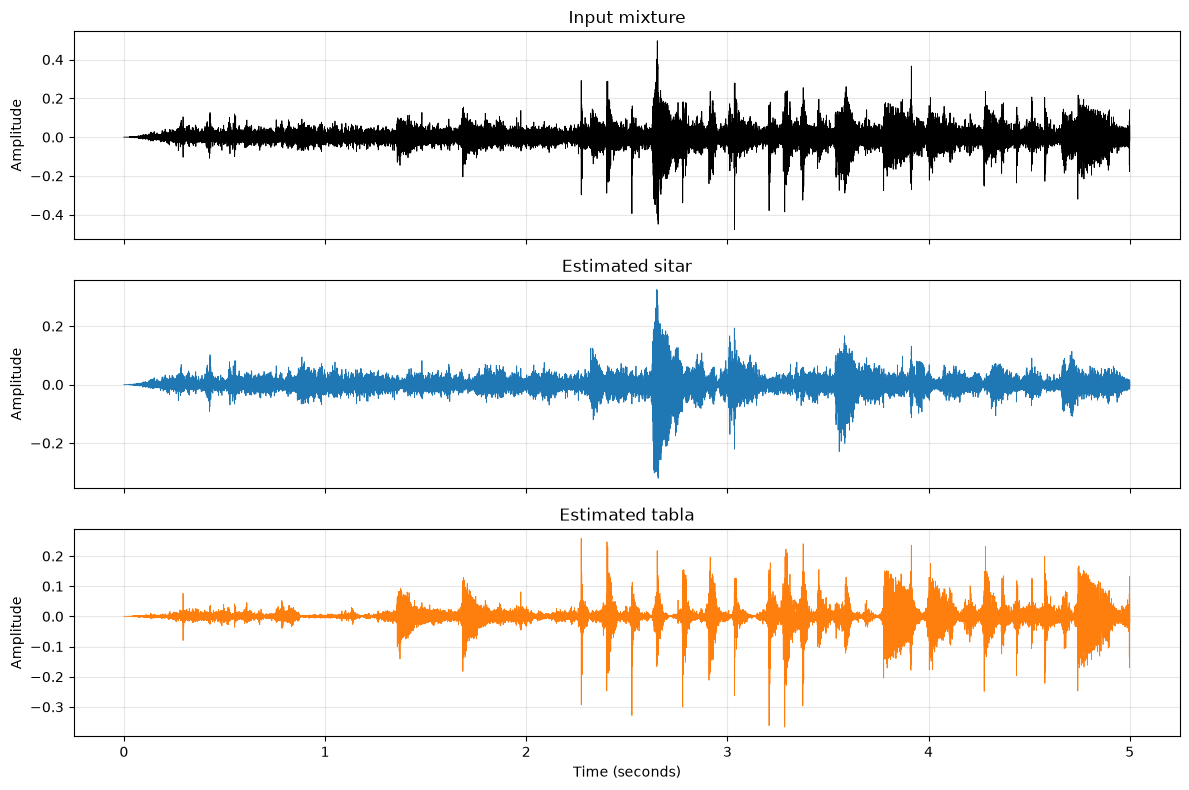

In [6]:
plot_samples = min(5 * sample_rate, number_of_samples)
plot_times = np.arange(plot_samples) / sample_rate
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for axis, name, color in zip(axes, ("mixture", "sitar", "tabla"), ("black", "tab:blue", "tab:orange")):
    audio = mixture_mono if name == "mixture" else estimates[name]
    axis.plot(plot_times, audio[:plot_samples], color=color, linewidth=0.6)
    axis.set_title("Input mixture" if name == "mixture" else f"Estimated {name}")
    axis.set_ylabel("Amplitude")
    axis.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (seconds)")
fig.tight_layout()
plt.show()

## Save the two estimates

This cell uses exclusive file creation and stops if either final filename already exists. It writes only the two estimated signals; the source recordings and original mixture are untouched. The WAVs use floating-point samples to avoid another PCM quantization step.

In [7]:
output_paths = {
    "sitar": output_dir / "sitar_estimate.wav",
    "tabla": output_dir / "tabla_estimate.wav",
}
existing_outputs = [str(path) for path in output_paths.values() if path.exists()]
if existing_outputs:
    raise FileExistsError(
        "Refusing to overwrite existing estimate(s): " + ", ".join(existing_outputs)
    )
output_dir.mkdir(parents=True, exist_ok=True)
for name, path in output_paths.items():
    with sf.SoundFile(
        path,
        mode="x",
        samplerate=sample_rate,
        channels=1,
        format="WAV",
        subtype="FLOAT",
    ) as output_file:
        output_file.write(estimates[name])

for name, path in output_paths.items():
    if not path.is_file() or path.stat().st_size == 0:
        raise IOError(f"Output was not written correctly: {path}")
    with sf.SoundFile(path) as output_file:
        if output_file.samplerate != sample_rate or output_file.channels != 1 or len(output_file) != number_of_samples:
            raise IOError(f"Saved output metadata is incorrect: {path}")
        saved_audio = output_file.read(dtype="float64", always_2d=True)
    if not np.isfinite(saved_audio).all():
        raise IOError(f"Saved output contains non-finite values: {path}")
    print(f"Saved and verified {name}: {path} ({path.stat().st_size:,} bytes)")

Saved and verified sitar: D:\indian-instrument-separation\outputs\supervised_nmf\sitar_estimate.wav (5,292,080 bytes)
Saved and verified tabla: D:\indian-instrument-separation\outputs\supervised_nmf\tabla_estimate.wav (5,292,080 bytes)
